# Check data

In [1]:
import pandas as pd
df = pd.read_csv('../data/adsorption/adsorption_gcmc_dataset.csv')
df.head()

,mol_uc_avg,n,temperature,adsorption_type,pressure
0,-17.854477,10,300,excess,1080000.0
1,0.003240,10,300,absolute,1080000.0
2,-17.797652,8,300,excess,1080000.0
3,1.168620,6,300,absolute,1080000.0
4,3.157465,4,300,excess,1080000.0


In [2]:
df.groupby('n').size().reset_index(name='count')

,n,count
0,2,242
1,4,242
2,6,242
3,8,242
4,10,242


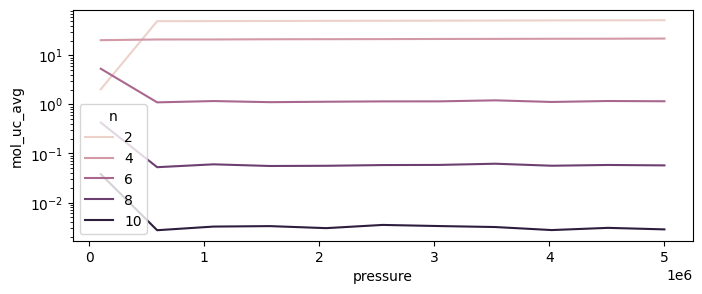

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(8, 3), dpi=100)

sns.lineplot(
    data=df.query('temperature == 300 and adsorption_type=="absolute"'),
    x='pressure',
    y='mol_uc_avg', hue='n')
ax.set_yscale('log')

# Make ml model

In [4]:
import pandas as pd
import numpy as np

data = pd.read_csv('../data/adsorption/adsorption_gcmc_dataset.csv')
data.head()

data['log_mol_uc_avg'] = data['mol_uc_avg'].apply(lambda x: -np.log10(np.abs(x)) if x < 0 else np.log10(x))
data['pressure_bar'] = data['pressure'] / 1e5
data['adsorption_type_num'] = data['adsorption_type'].map({'absolute': 0, 'excess': 1})

## Knn (works)

In [5]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
import joblib
from kinetic_model.constants.adsorption import AdsorptionKNN

# Example usage:
# 1) Fit and save model
ads_model = AdsorptionKNN(n_neighbors=2)
ads_model.fit(data, y_col='mol_uc_avg')
joblib.dump(ads_model, '../data/processed/knn_adsorption_model.pkl')

['../data/processed/knn_adsorption_model.pkl']

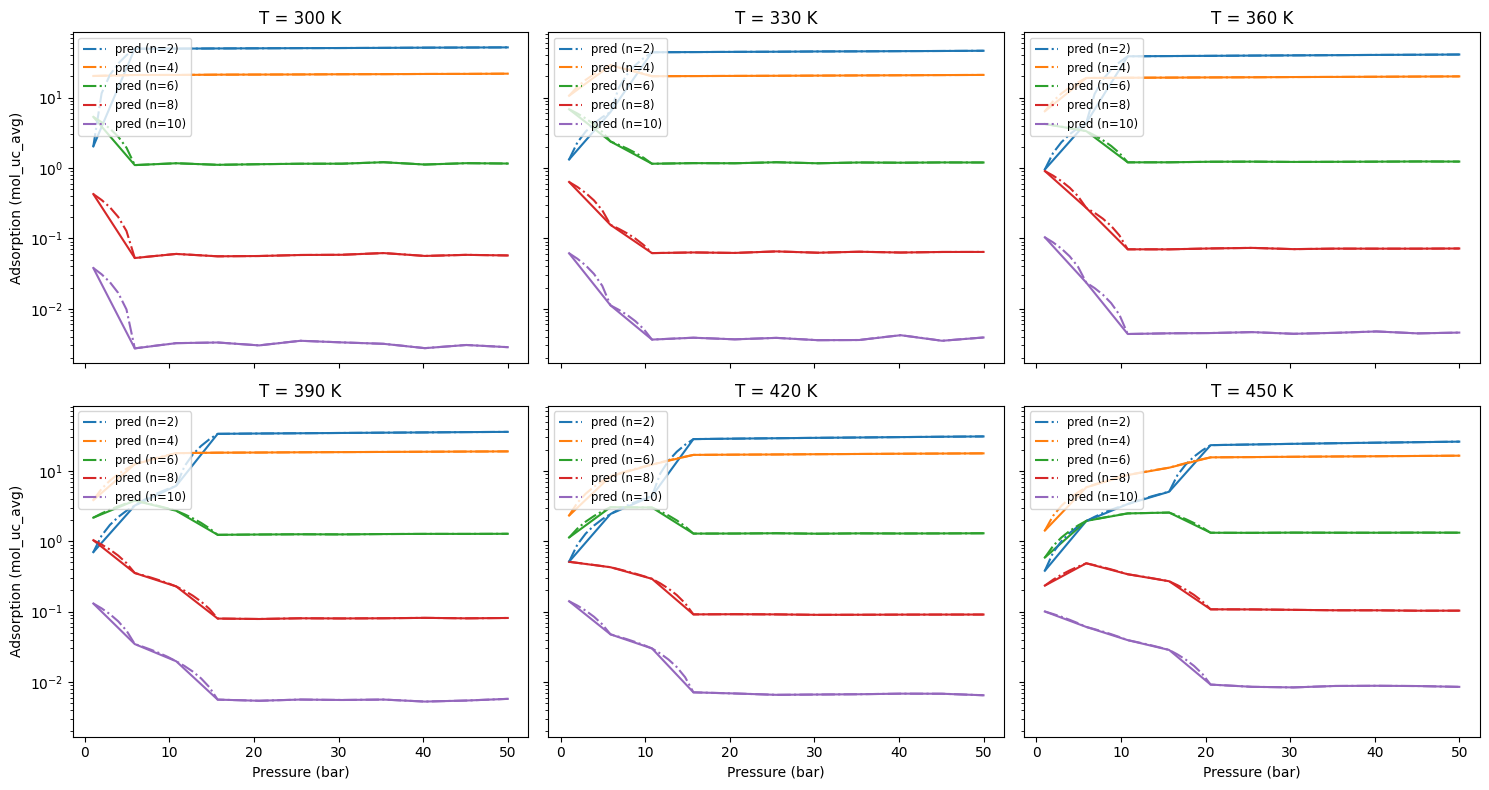

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# load your model and data
ads_model_loaded = joblib.load('../data/processed/knn_adsorption_model.pkl')

# define the six temperatures: 300, 330, 360, 390, 420, 450
temps = [300 + 30 * i for i in range(6)]

# keep your same color‐mapping
palette = dict(zip(
    range(2, 11, 2),
    sns.color_palette('tab10', n_colors=5)
))

# set up a 2×3 figure
fig, axes = plt.subplots(2, 3, figsize=(15, 8), dpi=100, sharex=True, sharey=True)
axes = axes.flatten()

# common pressure axis
m = 51
pressure = np.linspace(1, 50, m)

for ax, T in zip(axes, temps):
    # plot the existing data
    sns.lineplot(
        data=data.query(
            'temperature == @T and adsorption_type=="absolute"'
        ),
        x='pressure_bar', y='mol_uc_avg',
        hue='n', palette=palette,
        ax=ax, legend=False
    )

    # compute and plot predictions
    for n_val in range(2, 11, 2):
        X_test = pd.DataFrame({
            'pressure_bar': pressure,
            'temperature': [T] * m,
            'n':           [n_val] * m,
            'adsorption_type_num': [0] * m
        })
        y_pred = ads_model_loaded(X_test)
        ax.plot(
            pressure, y_pred,
            color=palette[n_val],
            linestyle='-.',
            label=f'pred (n={n_val})'
        )

    ax.set_yscale('log')
    ax.set_title(f'T = {T} K')
    ax.set_xlabel('Pressure (bar)')
    ax.set_ylabel('Adsorption (mol_uc_avg)')
    ax.legend(fontsize='small', loc='upper left')

fig.tight_layout()
plt.show()